In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
RANDOM_STATE = 42

In [2]:
df = pd.read_csv("heart_disease_datasets.csv")

print("Dataset loaded successfully.")
print(f"Shape: {df.shape}")
display(df.head())

Dataset loaded successfully.
Shape: (918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [ ]:
# Basic Insepction
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Column names:
['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS', 'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope', 'HeartDisease']

Data types:
Age                 int64
Sex                object
ChestPainType      object
RestingBP           int64
Cholesterol         int64
FastingBS           int64
RestingECG         object
MaxHR               int64
ExerciseAngina     object
Oldpeak           float64
ST_Slope           object
HeartDisease        int64
dtype: object

Missing values:
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

Duplicate rows: 0


In [4]:
# Dataset Summary
summary_df = pd.DataFrame({
    "Unique Values": df.nunique(),
    "Missing Values": df.isnull().sum(),
    "Data Type": df.dtypes.astype(str)
})

display(summary_df)

,Unique Values,Missing Values,Data Type
Age,50,0,int64
Sex,2,0,object
ChestPainType,4,0,object
RestingBP,67,0,int64
Cholesterol,222,0,int64
FastingBS,2,0,int64
RestingECG,3,0,object
MaxHR,119,0,int64
ExerciseAngina,2,0,object
Oldpeak,53,0,float64


Target distribution:
HeartDisease
0    410
1    508
Name: count, dtype: int64


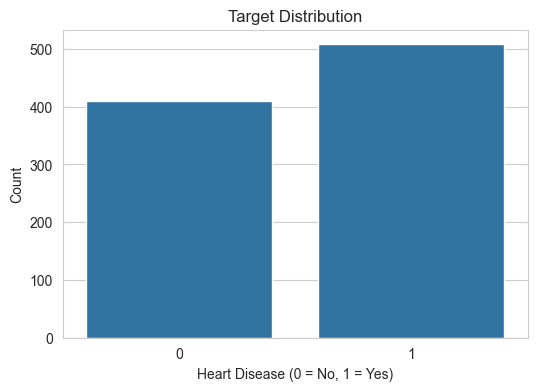

Class 0 percentage: 44.66%
Class 1 percentage: 55.34%


In [5]:
# Target Distribution
target_counts = df["HeartDisease"].value_counts().sort_index()
print("Target distribution:")
print(target_counts)

plt.figure(figsize=(6,4))
sns.countplot(data=df, x="HeartDisease")
plt.title("Target Distribution")
plt.xlabel("Heart Disease (0 = No, 1 = Yes)")
plt.ylabel("Count")
plt.show()

print(f"Class 0 percentage: {(target_counts[0] / len(df)) * 100:.2f}%")
print(f"Class 1 percentage: {(target_counts[1] / len(df)) * 100:.2f}%")

In [6]:
# Checking Suspicious values
print("Suspicious / potentially invalid values:")
print(f"Cholesterol == 0 : {(df['Cholesterol'] == 0).sum()}")
print(f"RestingBP == 0   : {(df['RestingBP'] == 0).sum()}")
print(f"MaxHR == 0       : {(df['MaxHR'] == 0).sum()}")
print(f"Oldpeak < 0      : {(df['Oldpeak'] < 0).sum()}")

Suspicious / potentially invalid values:
Cholesterol == 0 : 172
RestingBP == 0   : 1
MaxHR == 0       : 0
Oldpeak < 0      : 13


In [7]:
# cleaning invalid values
df_clean = df.copy()

# Replace medically implausible zero values with NaN so they can be imputed later
df_clean["Cholesterol"] = df_clean["Cholesterol"].replace(0, np.nan)
df_clean["RestingBP"] = df_clean["RestingBP"].replace(0, np.nan)

print("After replacing invalid zero values with NaN:")
print(df_clean[["Cholesterol", "RestingBP"]].isnull().sum())

After replacing invalid zero values with NaN:
Cholesterol    172
RestingBP        1
dtype: int64


In [8]:
# Separating numerical and categorical columns
target_col = "HeartDisease"

categorical_features = ["Sex", "ChestPainType", "RestingECG", "ExerciseAngina", "ST_Slope"]
numerical_features = ["Age", "RestingBP", "Cholesterol", "FastingBS", "MaxHR", "Oldpeak"]

X = df_clean.drop(columns=[target_col])
y = df_clean[target_col]

print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)

Categorical features: ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
Numerical features: ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak']


In [9]:
# Numerical statistics
display(df_clean[numerical_features].describe().T)

,count,mean,std,min,25%,50%,75%,max
Age,918.0,53.510893,9.432617,28.0,47.00,54.0,60.0,77.0
RestingBP,917.0,132.540894,17.999749,80.0,120.00,130.0,140.0,200.0
Cholesterol,746.0,244.635389,59.153524,85.0,207.25,237.0,275.0,603.0
FastingBS,918.0,0.233115,0.423046,0.0,0.00,0.0,0.0,1.0
MaxHR,918.0,136.809368,25.460334,60.0,120.00,138.0,156.0,202.0
Oldpeak,918.0,0.887364,1.066570,-2.6,0.00,0.6,1.5,6.2


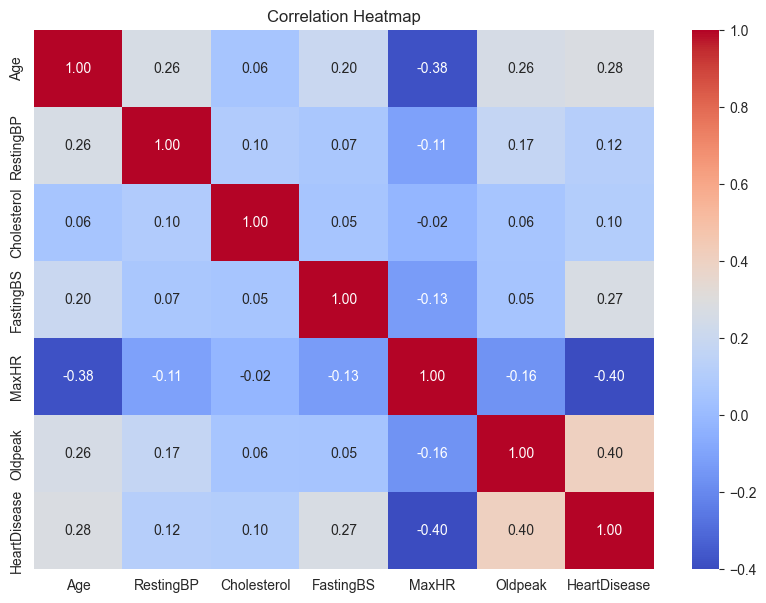

In [13]:
# Correlation heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(df_clean[numerical_features + [target_col]].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

In [14]:
# Quick EDA insights
print("Quick EDA Insights:")
print("- Cholesterol and RestingBP contain invalid zero values and need careful treatment.")
print("- The dataset is not severely imbalanced, so stratified splitting is sufficient.")
print("- Feature relationships should be interpreted carefully; correlation alone is not causation.")
print("- Since this is a medical prediction system, Recall is a priority metric.")

Quick EDA Insights:
- Cholesterol and RestingBP contain invalid zero values and need careful treatment.
- The dataset is not severely imbalanced, so stratified splitting is sufficient.
- Feature relationships should be interpreted carefully; correlation alone is not causation.
- Since this is a medical prediction system, Recall is a priority metric.


In [15]:
# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

Training set shape: (734, 11)
Testing set shape: (184, 11)


In [16]:
# Building preprocessing pipelines
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

In [17]:
# Defining baseline models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE, class_weight="balanced"),
    "SVM": SVC(probability=True, class_weight="balanced", random_state=RANDOM_STATE)
}

In [18]:
# Cross-validation comparision
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

results = []

for model_name, model in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])
    
    cv_result = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )
    
    results.append({
        "Model": model_name,
        "CV Accuracy": np.mean(cv_result["test_accuracy"]),
        "CV Precision": np.mean(cv_result["test_precision"]),
        "CV Recall": np.mean(cv_result["test_recall"]),
        "CV F1": np.mean(cv_result["test_f1"]),
        "CV ROC-AUC": np.mean(cv_result["test_roc_auc"])
    })

results_df = pd.DataFrame(results).sort_values(by="CV Recall", ascending=False)
display(results_df)

,Model,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC
1,Random Forest,0.855596,0.856601,0.891749,0.872675,0.926523
2,SVM,0.856975,0.864790,0.884312,0.873184,0.917026
0,Logistic Regression,0.836530,0.860338,0.844836,0.851619,0.921952


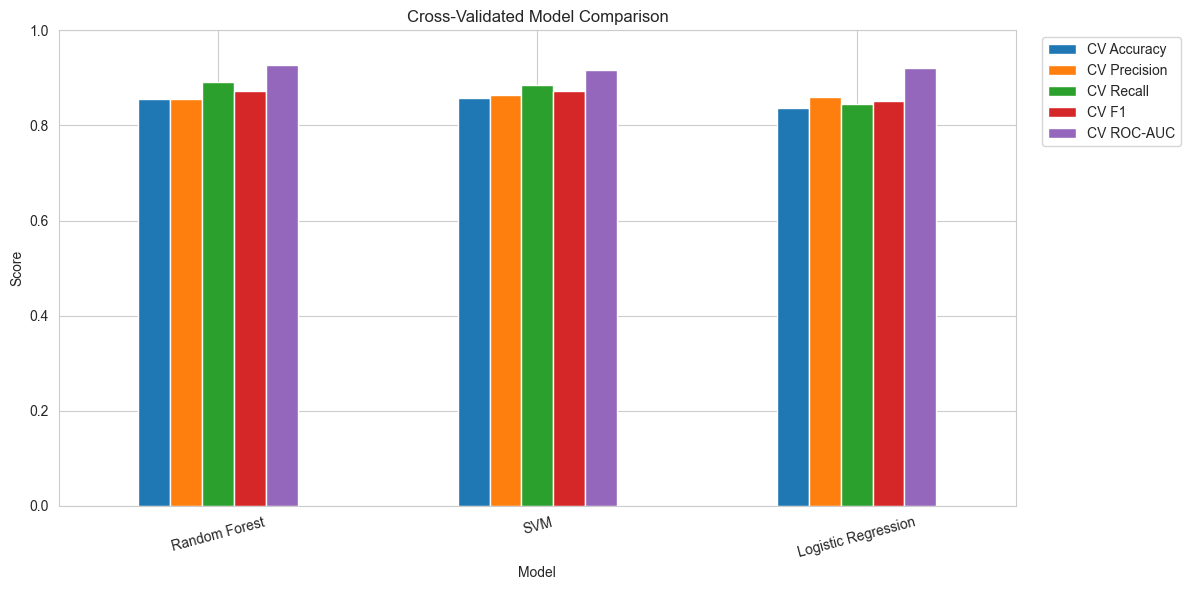

In [19]:
# visualizing model comparision
metric_cols = ["CV Accuracy", "CV Precision", "CV Recall", "CV F1", "CV ROC-AUC"]

results_df_plot = results_df.set_index("Model")[metric_cols]
results_df_plot.plot(kind="bar", figsize=(12, 6))
plt.title("Cross-Validated Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [20]:
# Random Forest tuning pipeline
rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        random_state=RANDOM_STATE,
        class_weight="balanced"
    ))
])

param_grid = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [None, 5, 10, 15],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4],
    "classifier__max_features": ["sqrt", "log2"]
}

grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring="recall",
    n_jobs=-1,
    verbose=1
)

In [21]:
# Fit tuned model
grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validated Recall:")
print(grid_search.best_score_)

Fitting 5 folds for each of 216 candidates, totalling 1080 fits
Best Parameters:
{'classifier__max_depth': None, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 300}

Best Cross-Validated Recall:
0.8990966576332429


In [22]:
#best model
best_model = grid_search.best_estimator_
print(best_model)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age', 'RestingBP',
                                                   'Cholesterol', 'FastingBS',
                                                   'MaxHR', 'Oldpeak']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                     

In [23]:
# test set predictions
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

In [24]:
# Final evaluation metrics
metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1 Score": f1_score(y_test, y_pred),
    "ROC-AUC": roc_auc_score(y_test, y_prob)
}

metrics_df = pd.DataFrame(metrics, index=["Test Score"]).T
display(metrics_df)

,Test Score
Accuracy,0.885870
Precision,0.885714
Recall,0.911765
F1 Score,0.898551
ROC-AUC,0.929101


In [25]:
# Classification Report
print("Classification Report:\n")
print(classification_report(y_test, y_pred, target_names=["No Heart Disease", "Heart Disease"]))

Classification Report:

                  precision    recall  f1-score   support

No Heart Disease       0.89      0.85      0.87        82
   Heart Disease       0.89      0.91      0.90       102

        accuracy                           0.89       184
       macro avg       0.89      0.88      0.88       184
    weighted avg       0.89      0.89      0.89       184



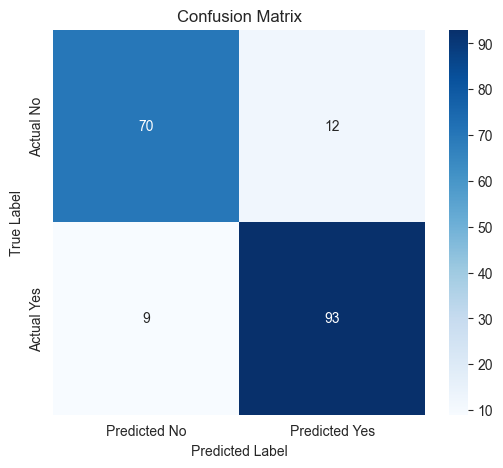

In [26]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Predicted No", "Predicted Yes"],
            yticklabels=["Actual No", "Actual Yes"])
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

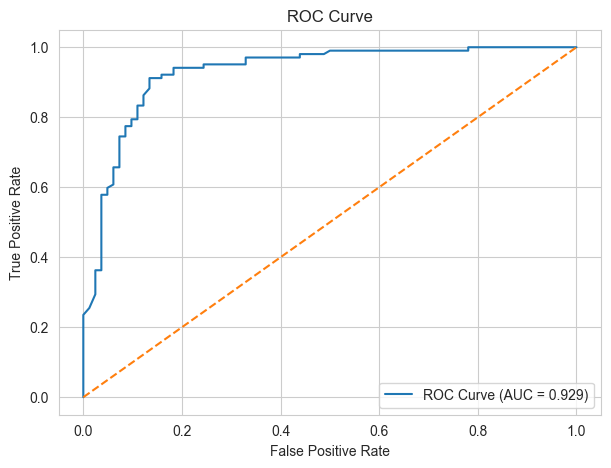

In [27]:
# ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(7,5))
plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {auc_score:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

In [28]:
# Feature Importance
rf_model = best_model.named_steps["classifier"]
ohe = best_model.named_steps["preprocessor"].named_transformers_["cat"].named_steps["onehot"]

encoded_cat_features = ohe.get_feature_names_out(categorical_features)
all_feature_names = numerical_features + list(encoded_cat_features)

feature_importance_df = pd.DataFrame({
    "Feature": all_feature_names,
    "Importance": rf_model.feature_importances_
}).sort_values(by="Importance", ascending=False)

display(feature_importance_df.head(15))

,Feature,Importance
19,ST_Slope_Up,0.153389
4,MaxHR,0.099823
18,ST_Slope_Flat,0.097616
5,Oldpeak,0.096157
8,ChestPainType_ASY,0.089943
2,Cholesterol,0.074832
0,Age,0.068205
1,RestingBP,0.067863
15,ExerciseAngina_N,0.057292
16,ExerciseAngina_Y,0.048563


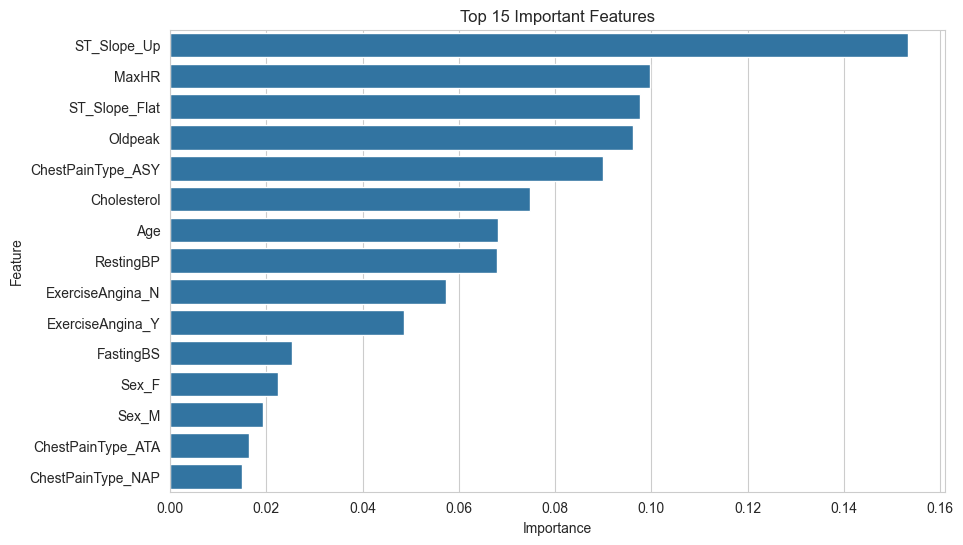

In [29]:
# Plotting top feature importances
top_n = 15
plt.figure(figsize=(10, 6))
sns.barplot(
    data=feature_importance_df.head(top_n),
    x="Importance",
    y="Feature"
)
plt.title(f"Top {top_n} Important Features")
plt.show()

In [30]:
joblib.dump(best_model, "heart_disease_pipeline.joblib")
print("Final pipeline saved as 'heart_disease_pipeline.joblib'")

Final pipeline saved as 'heart_disease_pipeline.joblib'
